# Лабораторная работа №2 — Классификация

Данные: [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset). Целевая переменная: `Survived` (1 — выжил, 0 — не выжил).

Основная метрика: F1-score для класса 1. Требование задания: **F1 > 0.70**


In [1]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    TunedThresholdClassifierCV,
)
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)
import sklearn

SEED = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
from joblib import parallel_backend

Python: 3.13.5
scikit-learn: 1.6.1


## 1. Данные

Используем исходный CSV с Kaggle. Проверяем структуру, пропуски и полные дубликаты.

In [2]:
data_path = Path("data/Titanic-Dataset.csv")
if not data_path.exists():
    data_path = Path("classification/data/Titanic-Dataset.csv")
data = pd.read_csv(data_path)

print("Размер:", data.shape)
print("Полных дубликатов:", data.duplicated().sum())
display(data.head())
display(pd.DataFrame({
    "Тип": data.dtypes.astype(str),
    "Пропуски": data.isna().sum(),
    "Пропуски, %": (data.isna().mean() * 100).round(2),
}))

Размер: (891, 12)
Полных дубликатов: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Тип,Пропуски,"Пропуски, %"
PassengerId,int64,0,0.00
Survived,int64,0,0.00
Pclass,int64,0,0.00
Name,object,0,0.00
Sex,object,0,0.00
Age,float64,177,19.87
SibSp,int64,0,0.00
Parch,int64,0,0.00
Ticket,object,0,0.00
Fare,float64,0,0.00


## 2. Разделение данных

Выделяем 20% данных для контрольной оценки: 712 пассажиров в train и 179 в test. Стратификация сохраняет соотношение классов, `random_state=42` фиксирует разбиение. Параметры и пороги подбираем на train.


In [3]:
X = data.drop(columns="Survived")
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, "| Контроль:", X_test.shape)
display(pd.DataFrame({
    "Train, %": y_train.value_counts(normalize=True) * 100,
    "Контроль, %": y_test.value_counts(normalize=True) * 100,
}).sort_index().round(2))

Train: (712, 11) | Контроль: (179, 11)


,"Train, %","Контроль, %"
Survived,,
0,61.66,61.45
1,38.34,38.55


## 3. Признаки

Из имени извлекаем только обращение `Title`; само имя и идентификаторы не используем. Добавляем размер семьи, одиночное путешествие, наличие каюты, палубу, индикатор пропущенного возраста и логарифмы стоимости билета и стоимости на члена семьи.

Правила извлечения фиксированы и не используют `Survived`. Медианы и категории кодировщика будут обучаться внутри Pipeline.

In [4]:
NUMERIC = ['Age',
 'SibSp',
 'Parch',
 'FamilySize',
 'IsAlone',
 'LogFare',
 'LogFarePerPerson',
 'HasCabin',
 'AgeMissing']
CATEGORICAL = ['Pclass', 'Sex', 'Embarked', 'Title', 'Deck']

def build_features(frame):
    result = frame.copy()
    result["FamilySize"] = result["SibSp"] + result["Parch"] + 1
    result["IsAlone"] = (result["FamilySize"] == 1).astype(int)
    result["HasCabin"] = result["Cabin"].notna().astype(int)
    result["AgeMissing"] = result["Age"].isna().astype(int)
    result["LogFare"] = np.log1p(result["Fare"].clip(lower=0))
    result["LogFarePerPerson"] = np.log1p(
        result["Fare"].clip(lower=0) / result["FamilySize"]
    )
    title = result["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    result["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    result["Deck"] = result["Cabin"].str[0].fillna("Unknown")
    return result[NUMERIC + CATEGORICAL]

print("Числовые:", NUMERIC)
print("Категориальные:", CATEGORICAL)
display(build_features(X_train).head())

Числовые: ['Age', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'LogFare', 'LogFarePerPerson', 'HasCabin', 'AgeMissing']
Категориальные: ['Pclass', 'Sex', 'Embarked', 'Title', 'Deck']


,Age,SibSp,Parch,FamilySize,IsAlone,LogFare,LogFarePerPerson,HasCabin,AgeMissing,Pclass,Sex,Embarked,Title,Deck
692,NaN,0,0,1,1,4.051712,4.051712,0,1,3,male,S,Mr,Unknown
481,NaN,0,0,1,1,0.000000,0.000000,0,1,2,male,S,Mr,Unknown
527,NaN,0,0,1,1,5.406181,5.406181,1,1,1,male,S,Mr,C
855,18.0,0,1,2,0,2.336987,1.736071,0,0,3,female,S,Mrs,Unknown
801,31.0,1,1,3,0,3.305054,2.277267,0,0,2,female,S,Mrs,Unknown


## 4. EDA на train

Сравниваем долю выживших по полу, классу билета и обращению. Размеры групп показываем рядом с долями.

,Пассажиров,"Выжили, %"
Sex,,
female,253,74.31
male,459,18.52


,Пассажиров,"Выжили, %"
Pclass,,
1,171,64.91
2,150,44.67
3,391,24.30


,Пассажиров,"Выжили, %"
Title,,
Master,31,54.84
Miss,144,70.83
Mr,412,15.29
Mrs,107,78.50
Rare,18,38.89


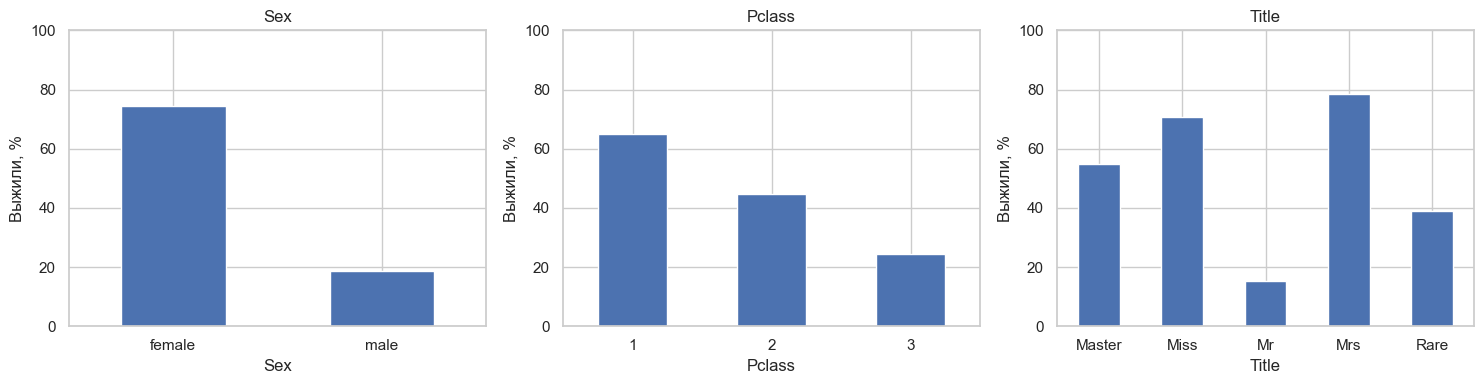

In [5]:
train_view = X_train.assign(Survived=y_train)
train_features = build_features(X_train).assign(Survived=y_train)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for feature, ax in zip(["Sex", "Pclass", "Title"], axes):
    stats = train_features.groupby(feature)["Survived"].agg(["size", "mean"])
    stats.columns = ["Пассажиров", "Выжили, %"]
    stats["Выжили, %"] = (stats["Выжили, %"] * 100).round(2)
    display(stats)
    stats["Выжили, %"].plot.bar(ax=ax, rot=0)
    ax.set(title=feature, ylabel="Выжили, %", ylim=(0, 100))

plt.tight_layout()
plt.show()

Доля выживших различается по полу, классу и обращению. Это наблюдаемые связи, а не причинные эффекты.

,r с Survived
IsFemale,0.549
LogFare,0.355
HasCabin,0.351
Pclass,-0.348
LogFarePerPerson,0.315
IsAlone,-0.216
AgeMissing,-0.092
Age,-0.084
Parch,0.084
FamilySize,0.027


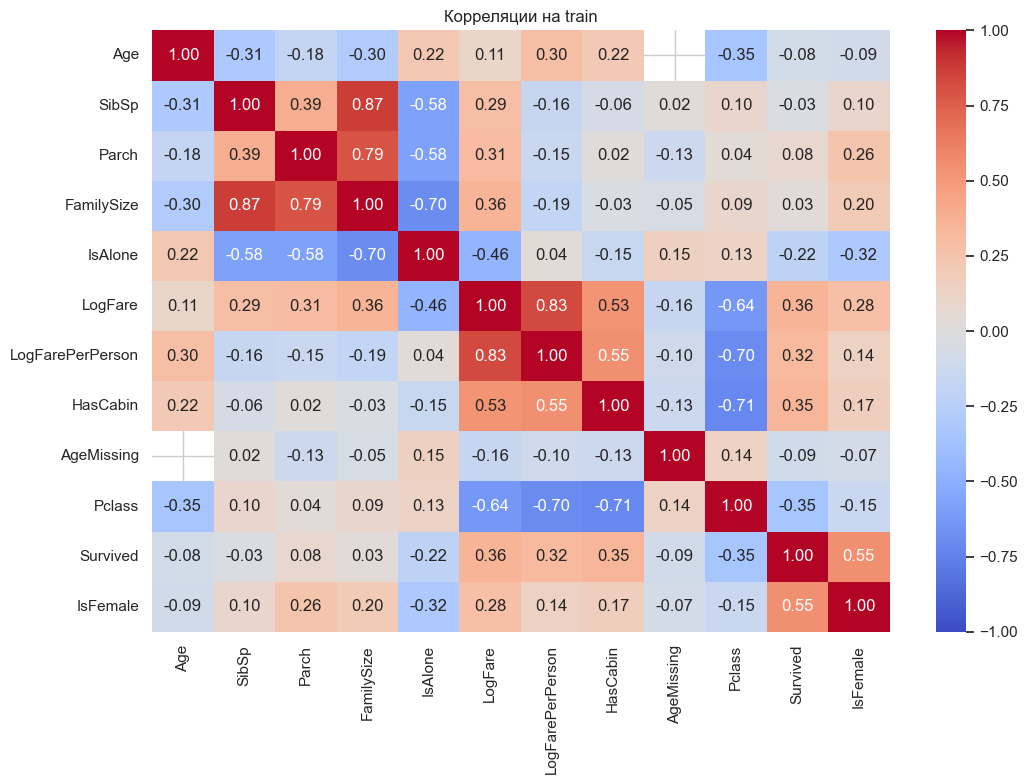

In [6]:
correlation_view = train_features[NUMERIC + ["Pclass", "Survived"]].copy()
correlation_view["IsFemale"] = (train_features["Sex"] == "female").astype(int)
correlation = correlation_view.corr()

display(correlation["Survived"].drop("Survived").sort_values(
    key=lambda values: values.abs(), ascending=False,
).round(3).to_frame("r с Survived"))

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Корреляции на train")
plt.tight_layout()
plt.show()

Корреляции возраста считаются по непустым парам. Слабая линейная корреляция не исключает нелинейную связь; связанные признаки могут делить важность между собой.

## 5. Предобработка

Числовые пропуски заполняем медианой, категориальные — наиболее частым значением. Категории кодируем One-Hot. Для SVM и KNN масштабируем числовые признаки. В каждой CV-итерации Pipeline обучает преобразования заново.

In [7]:
def make_pipeline(classifier, scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), NUMERIC),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL),
    ], remainder="drop", verbose_feature_names_out=False)

    return Pipeline([
        ("features", FunctionTransformer(build_features)),
        ("preprocessor", preprocessor),
        ("model", clone(classifier)),
    ])


## 6. Подбор параметров и кросс-валидация

Используем 5 внешних и 3 внутренних стратифицированных фолда. На внутренних фолдах `GridSearchCV` выбирает параметры по F1, затем `TunedThresholdClassifierCV` подбирает порог решения. На внешнем фолде оцениваем модель, не используя его ответы при настройке. Предобработка обучается внутри Pipeline.

Порог определяет, какое значение оценки модели считать классом 1. Его подбор позволяет изменить баланс Precision и Recall. F1 — их гармоническое среднее: `2 × Precision × Recall / (Precision + Recall)`.

После кросс-валидации настраиваем модель на всём train. В разделах ниже явно задаём алгоритм, сетку параметров и необходимость масштабирования; общая функция возвращает модель и метрики.


In [8]:
def metrics(actual, predicted):
    return {
        "Accuracy": float(accuracy_score(actual, predicted)),
        "Precision": float(precision_score(actual, predicted, zero_division=0)),
        "Recall": float(recall_score(actual, predicted, zero_division=0)),
        "F1": float(f1_score(actual, predicted, zero_division=0)),
    }


def train_model(pipeline, param_grid, frame, target):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    search = GridSearchCV(
        clone(pipeline), param_grid, scoring="f1",
        cv=inner, n_jobs=2, pre_dispatch=2, error_score="raise",
    )
    with parallel_backend("threading"):
        search.fit(frame, target)
    tuned = TunedThresholdClassifierCV(
        search.best_estimator_, scoring="f1", cv=inner,
        thresholds=51, n_jobs=1, refit=True,
    )
    tuned.fit(frame, target)
    info = {
        "params": search.best_params_,
        "search_f1": float(search.best_score_),
        "threshold_f1": float(tuned.best_score_),
        "threshold": float(tuned.best_threshold_),
    }
    return tuned, info


def evaluate_model(name, pipeline, param_grid):
    predictions = np.empty(len(y_train), dtype=int)
    fold_info = []
    started = time.time()

    for fold, (fit_idx, validation_idx) in enumerate(
        outer_cv.split(X_train, y_train), start=1
    ):
        print(f"{name}: внешний фолд {fold}/5", flush=True)
        fitted, info = train_model(
            pipeline, param_grid, X_train.iloc[fit_idx], y_train.iloc[fit_idx],
        )
        current = fitted.predict(X_train.iloc[validation_idx])
        predictions[validation_idx] = current
        info["fold"] = fold
        info["validation"] = metrics(y_train.iloc[validation_idx], current)
        fold_info.append(info)

    final_model, final_info = train_model(pipeline, param_grid, X_train, y_train)
    result = {
        "model": final_model,
        "oof": predictions,
        "nested": metrics(y_train, predictions),
        "train": metrics(y_train, final_model.predict(X_train)),
        "info": final_info,
        "fold_info": fold_info,
    }
    print("Параметры на полном train:", final_info["params"])
    print("Порог на полном train:", round(final_info["threshold"], 4))
    print("Время, с:", round(time.time() - started, 1))
    display(pd.DataFrame({
        "Train": result["train"],
        "Внешняя CV": result["nested"],
    }).T.round(4))
    return result

results = {}

## 7. Dummy baseline

Всегда предсказывает наиболее частый класс. Baseline не обязан проходить порог 0.70.

In [9]:
dummy = DummyClassifier(strategy="most_frequent")
dummy_oof = cross_val_predict(dummy, X_train, y_train, cv=outer_cv)
dummy.fit(X_train, y_train)
results["Dummy"] = {
    "model": dummy,
    "oof": dummy_oof,
    "nested": metrics(y_train, dummy_oof),
    "train": metrics(y_train, dummy.predict(X_train)),
}
display(pd.DataFrame([results["Dummy"]["nested"]], index=["Dummy"]).round(4))

,Accuracy,Precision,Recall,F1
Dummy,0.6166,0.0,0.0,0.0


У Dummy F1 для выживших равен 0, хотя Accuracy около 0.62: одной Accuracy недостаточно.

## 8. Дерево решений

Дерево последовательно делит пассажиров по признакам. `max_depth` ограничивает глубину, `min_samples_leaf` — минимальное число пассажиров в листе. `class_weight="balanced"` увеличивает вес менее частого класса.


In [10]:
tree_classifier = DecisionTreeClassifier(random_state=SEED)

tree_param_grid = {
    'model__max_depth': [3, 4, 5, 6, 8],
    'model__min_samples_leaf': [3, 8, 15],
    'model__class_weight': [None, 'balanced'],
}

tree_pipeline = make_pipeline(
    tree_classifier, scale_numeric=False,
)

results['Decision Tree'] = evaluate_model(
    'Decision Tree', tree_pipeline, tree_param_grid,
)


Decision Tree: внешний фолд 1/5


Decision Tree: внешний фолд 2/5


Decision Tree: внешний фолд 3/5


Decision Tree: внешний фолд 4/5


Decision Tree: внешний фолд 5/5


Параметры на полном train: {'model__class_weight': 'balanced', 'model__max_depth': 4, 'model__min_samples_leaf': 3}
Порог на полном train: 0.48
Время, с: 54.2


,Accuracy,Precision,Recall,F1
Train,0.8567,0.7958,0.8425,0.8185
Внешняя CV,0.8230,0.7634,0.7802,0.7717


У дерева F1 на train = 0.8185, по внешней CV = 0.7717. Разрыв умеренный: ограничение глубины и размера листа сдерживает переобучение.


## 9. Случайный лес

Лес объединяет прогнозы 160 деревьев, обученных на случайных подвыборках. Подбираем глубину (`max_depth`), минимальный размер листа (`min_samples_leaf`) и число признаков при разбиении (`max_features`). Разнообразие деревьев помогает уменьшить переобучение.


In [11]:
forest_classifier = RandomForestClassifier(
    n_estimators=160,
    random_state=SEED,
    n_jobs=1,
)

forest_param_grid = {
    'model__max_depth': [5, 8, None],
    'model__min_samples_leaf': [2, 5],
    'model__max_features': ['sqrt', 0.8],
}

forest_pipeline = make_pipeline(
    forest_classifier, scale_numeric=False,
)

results['Random Forest'] = evaluate_model(
    'Random Forest', forest_pipeline, forest_param_grid,
)


Random Forest: внешний фолд 1/5


Random Forest: внешний фолд 2/5


Random Forest: внешний фолд 3/5


Random Forest: внешний фолд 4/5


Random Forest: внешний фолд 5/5


Параметры на полном train: {'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 2}
Порог на полном train: 0.5025
Время, с: 180.5


,Accuracy,Precision,Recall,F1
Train,0.9242,0.9363,0.8608,0.8969
Внешняя CV,0.8188,0.7483,0.7949,0.7709


У леса F1 на train = 0.8969, по внешней CV = 0.7709. Качество почти совпало с деревом, а разрыв с train больше. В этом сравнении ансамбль не дал заметного прироста F1.


## 10. Градиентный бустинг

Деревья строятся последовательно: каждое уточняет прогноз ансамбля. Подбираем число деревьев (`n_estimators`), скорость обучения (`learning_rate`) и глубину (`max_depth`). Меньшая скорость уменьшает вклад каждого дерева.


In [12]:
boosting_classifier = GradientBoostingClassifier(
    min_samples_leaf=5,
    random_state=SEED,
)

boosting_param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [1, 2, 3],
}

boosting_pipeline = make_pipeline(
    boosting_classifier, scale_numeric=False,
)

results['Gradient Boosting'] = evaluate_model(
    'Gradient Boosting', boosting_pipeline, boosting_param_grid,
)


Gradient Boosting: внешний фолд 1/5


Gradient Boosting: внешний фолд 2/5


Gradient Boosting: внешний фолд 3/5


Gradient Boosting: внешний фолд 4/5


Gradient Boosting: внешний фолд 5/5


Параметры на полном train: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
Порог на полном train: 0.3401
Время, с: 117.0


,Accuracy,Precision,Recall,F1
Train,0.8933,0.8385,0.8938,0.8652
Внешняя CV,0.8118,0.7663,0.7326,0.7491


У бустинга F1 на train = 0.8652, по внешней CV = 0.7491. Разрыв указывает на переобучение; на проверочных фолдах он уступает дереву и лесу.


## 11. SVM

RBF-ядро позволяет строить нелинейную границу классов по расстояниям между объектами. `C` задаёт штраф за ошибки, `gamma` — насколько локально влияние отдельных объектов. Числовые признаки масштабируем. Порог подбирается для `decision_function`, поэтому он может быть отрицательным.


In [13]:
svm_classifier = SVC(kernel="rbf")

svm_param_grid = {
    'model__C': [0.1, 1, 10, 30],
    'model__gamma': ['scale', 0.01, 0.1],
}

svm_pipeline = make_pipeline(
    svm_classifier, scale_numeric=True,
)

results['SVM'] = evaluate_model(
    'SVM', svm_pipeline, svm_param_grid,
)


SVM: внешний фолд 1/5


SVM: внешний фолд 2/5


SVM: внешний фолд 3/5


SVM: внешний фолд 4/5


SVM: внешний фолд 5/5


Параметры на полном train: {'model__C': 1, 'model__gamma': 'scale'}
Порог на полном train: -0.3278
Время, с: 29.2


,Accuracy,Precision,Recall,F1
Train,0.8553,0.8220,0.7949,0.8082
Внешняя CV,0.8104,0.7594,0.7399,0.7495


У SVM F1 на train = 0.8082, по внешней CV = 0.7495. Разрыв меньше, чем у леса и бустинга, но F1 ниже, чем у дерева. Масштабирование нужно, поскольку RBF-ядро зависит от расстояний.


## 12. KNN

Прогноз строится по ближайшим пассажирам в пространстве признаков. Подбираем число соседей (`n_neighbors`), равные или зависящие от расстояния веса (`weights`) и метрику: `p=1` — манхэттенское расстояние, `p=2` — евклидово. Числовые признаки масштабируем.


In [14]:
knn_classifier = KNeighborsClassifier()

knn_param_grid = {
    'model__n_neighbors': [5, 9, 15, 25],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}

knn_pipeline = make_pipeline(
    knn_classifier, scale_numeric=True,
)

results['KNN'] = evaluate_model(
    'KNN', knn_pipeline, knn_param_grid,
)


KNN: внешний фолд 1/5


KNN: внешний фолд 2/5


KNN: внешний фолд 3/5


KNN: внешний фолд 4/5


KNN: внешний фолд 5/5


Параметры на полном train: {'model__n_neighbors': 15, 'model__p': 2, 'model__weights': 'distance'}
Порог на полном train: 0.26
Время, с: 33.9


,Accuracy,Precision,Recall,F1
Train,0.9846,0.9645,0.9963,0.9802
Внешняя CV,0.7907,0.7214,0.7399,0.7306


У KNN F1 на train = 0.9802, по внешней CV = 0.7306: разрыв самый большой. При весах `distance` обучающий объект имеет нулевое расстояние до самого себя, поэтому высокая оценка на train ожидаема и не отражает качество на новых пассажирах.


## 13. Сравнение по внешней CV

Для каждого пассажира train используем прогноз модели, при подборе которой этот пассажир находился только во внешнем проверочном фолде. Порог проверяем по объединённым OOF-прогнозам каждой модели.

In [15]:
model_names = [name for name in results if name != "Dummy"]
cv_table = pd.DataFrame({
    name: item["nested"] for name, item in results.items()
}).T
cv_table["F1 > 0.70"] = cv_table["F1"] > 0.70
display(cv_table.round(4))

best_name = max(model_names, key=lambda name: results[name]["nested"]["F1"])
best_model = results[best_name]["model"]
print("Выбрана по внешней CV:", best_name)
print("Все пять моделей выше 0.70 по внешней CV:",
      bool((cv_table.loc[model_names, "F1"] > 0.70).all()))

,Accuracy,Precision,Recall,F1,F1 > 0.70
Dummy,0.6166,0.0000,0.0000,0.0000,False
Decision Tree,0.8230,0.7634,0.7802,0.7717,True
Random Forest,0.8188,0.7483,0.7949,0.7709,True
Gradient Boosting,0.8118,0.7663,0.7326,0.7491,True
SVM,0.8104,0.7594,0.7399,0.7495,True
KNN,0.7907,0.7214,0.7399,0.7306,True


Выбрана по внешней CV: Decision Tree
Все пять моделей выше 0.70 по внешней CV: True


## 14. Важность признаков

Суммируем важности One-Hot столбцов по исходным признакам. Сравниваем финальные дерево, лес и бустинг. Важности отражают снижение неоднородности, а не причинное влияние.

,Decision Tree,Random Forest,Gradient Boosting
Title,0.6311,0.2224,0.4756
Sex,0.0000,0.2135,0.0306
LogFarePerPerson,0.1303,0.1385,0.1220
Age,0.0116,0.1162,0.0771
LogFare,0.0424,0.0928,0.0680
Pclass,0.0578,0.0791,0.1106
FamilySize,0.1131,0.0392,0.0572
Deck,0.0138,0.0315,0.0241
Embarked,0.0000,0.0246,0.0190
HasCabin,0.0000,0.0158,0.0101


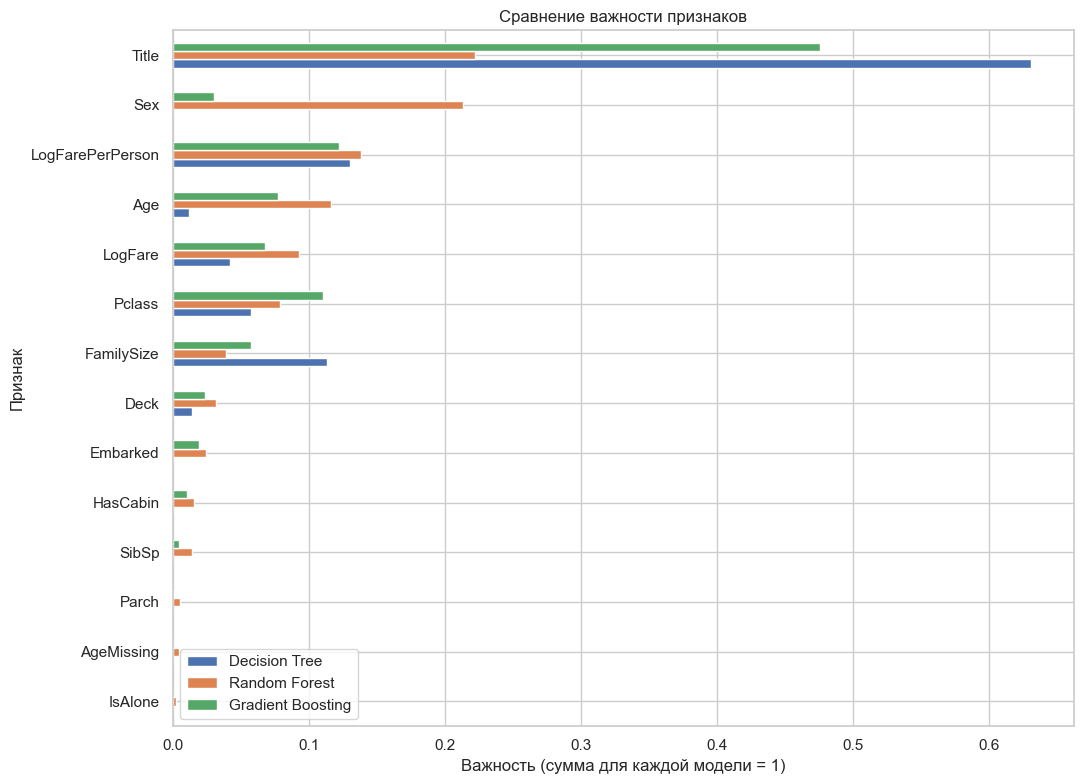

In [16]:
importance = {}
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:
    pipeline = results[name]["model"].estimator_
    names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    values = pd.Series(
        pipeline.named_steps["model"].feature_importances_, index=names,
    )
    importance[name] = values.groupby(
        lambda feature: feature.split("_")[0]
    ).sum()

importance_table = pd.DataFrame(importance).fillna(0)
importance_table = importance_table.sort_values("Random Forest", ascending=False)
display(importance_table.round(4))
importance_table.iloc[::-1].plot.barh(figsize=(11, 8))
plt.xlabel("Важность (сумма для каждой модели = 1)")
plt.ylabel("Признак")
plt.title("Сравнение важности признаков")
plt.tight_layout()
plt.show()

В дереве лидирует `Title` (0.631), затем стоимость на члена семьи (0.130) и размер семьи (0.113). Лес распределяет важность между `Title` (0.222), полом (0.214), стоимостью на члена семьи и возрастом. У бустинга также лидирует `Title` (0.476). Обращение связано с полом и возрастом, поэтому нулевая отдельная важность `Sex` у дерева не означает отсутствие информации о поле. Это согласуется с EDA по обращениям; важности не являются причинными эффектами.

## 15. Оценка на контрольной выборке

Сравниваем все модели на одном test. Считаем Accuracy, Precision, Recall и F1, проверяем превышение порога 0.70.


In [17]:
test_predictions = {}
test_metrics = {}
for name, item in results.items():
    test_predictions[name] = item["model"].predict(X_test)
    test_metrics[name] = metrics(y_test, test_predictions[name])

test_table = pd.DataFrame.from_dict(test_metrics, orient="index")
test_table["F1 > 0.70"] = test_table["F1"] > 0.70
display(test_table.round(4))

f1_comparison = pd.DataFrame({
    "Train F1": {name: item["train"]["F1"] for name, item in results.items()},
    "Внешняя CV F1": {name: item["nested"]["F1"] for name, item in results.items()},
    "Контроль F1": test_table["F1"],
})
display(f1_comparison.round(4))

all_cv_pass = bool((cv_table.loc[model_names, "F1"] > 0.70).all())
all_control_pass = bool((test_table.loc[model_names, "F1"] > 0.70).all())
print("Все пять моделей: F1 > 0.70 по внешней CV:", all_cv_pass)
print("Все пять моделей: F1 > 0.70 на контрольной выборке:", all_control_pass)

,Accuracy,Precision,Recall,F1,F1 > 0.70
Dummy,0.6145,0.0000,0.0000,0.0000,False
Decision Tree,0.8156,0.7432,0.7971,0.7692,True
Random Forest,0.7877,0.7541,0.6667,0.7077,True
Gradient Boosting,0.7821,0.6875,0.7971,0.7383,True
SVM,0.8268,0.7879,0.7536,0.7704,True
KNN,0.7263,0.6020,0.8551,0.7066,True


,Train F1,Внешняя CV F1,Контроль F1
Dummy,0.0000,0.0000,0.0000
Decision Tree,0.8185,0.7717,0.7692
Random Forest,0.8969,0.7709,0.7077
Gradient Boosting,0.8652,0.7491,0.7383
SVM,0.8082,0.7495,0.7704
KNN,0.9802,0.7306,0.7066


Все пять моделей: F1 > 0.70 по внешней CV: True
Все пять моделей: F1 > 0.70 на контрольной выборке: True


## 16. Матрицы ошибок

Положительный класс — выжил. FP означает ошибочное предсказание выживания, FN — ошибочное предсказание гибели.

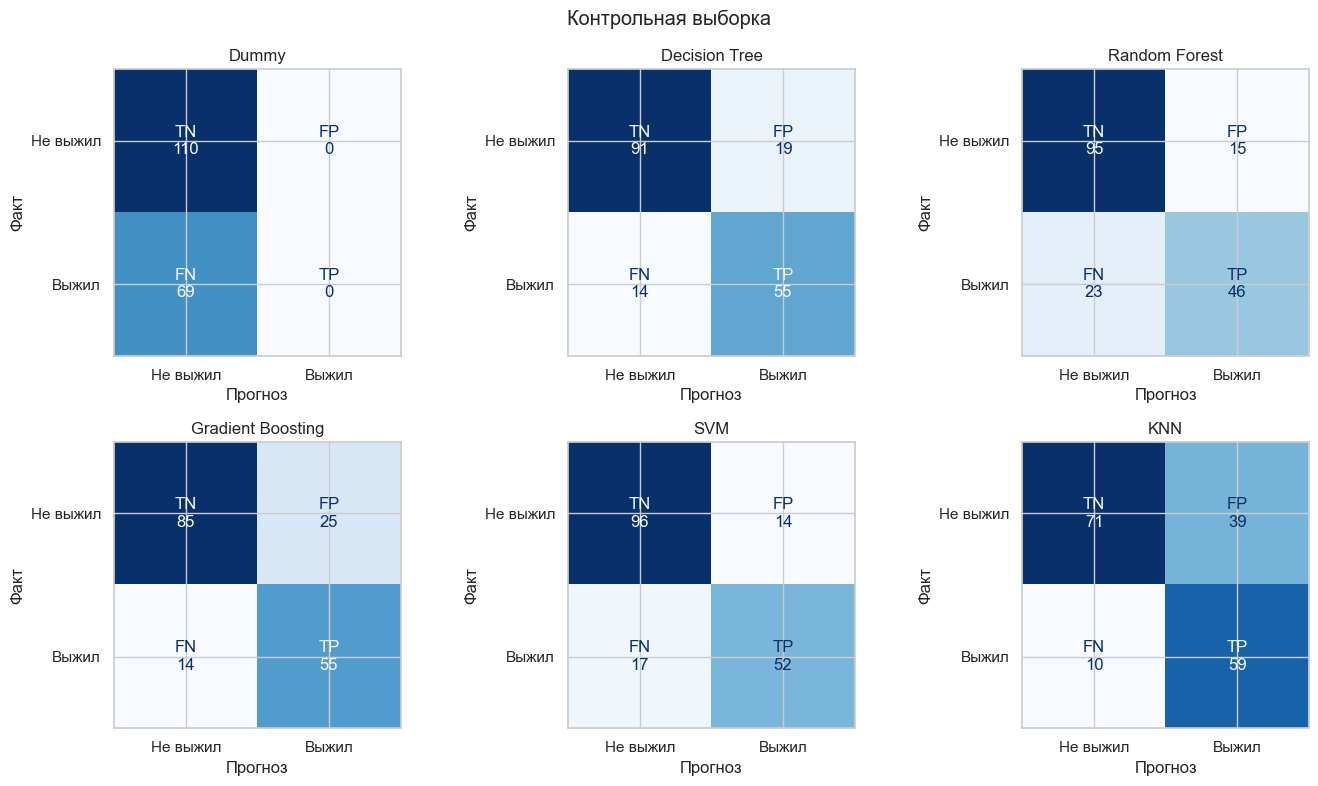

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for (name, predictions), ax in zip(test_predictions.items(), axes.ravel()):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=["Не выжил", "Выжил"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    for label, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
        text.set_text(f"{label}\n{text.get_text()}")
    ax.set(title=name, xlabel="Прогноз", ylabel="Факт")
plt.suptitle("Контрольная выборка")
plt.tight_layout()
plt.show()

## 17. Анализ ошибок выбранной модели

Анализируем ошибки модели с наибольшим F1 по внешней CV. Параметры после просмотра ошибок не меняем.


In [19]:
error_analysis = X_test.assign(
    Actual=y_test, Predicted=test_predictions[best_name],
)
error_analysis["Error"] = error_analysis["Actual"] != error_analysis["Predicted"]
error_analysis["FP"] = (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 1)
error_analysis["FN"] = (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 0)

print("Модель:", best_name)
print("FP:", int(error_analysis["FP"].sum()),
      "| FN:", int(error_analysis["FN"].sum()))
group_errors = error_analysis.groupby(["Sex", "Pclass"]).agg(
    n=("Error", "size"), errors=("Error", "sum"),
    FP=("FP", "sum"), FN=("FN", "sum"),
)
group_errors["Ошибки, %"] = (100 * group_errors["errors"] / group_errors["n"]).round(2)
display(group_errors.sort_values("Ошибки, %", ascending=False))

if hasattr(best_model, "predict_proba"):
    error_analysis["Score"] = best_model.predict_proba(X_test)[:, 1]
else:
    error_analysis["Score"] = best_model.decision_function(X_test)

wrong = error_analysis[error_analysis["Error"]].copy()
wrong["Type"] = np.where(wrong["FP"], "FP", "FN")
wrong["Margin"] = abs(wrong["Score"] - best_model.best_threshold_)
examples = (
    wrong.sort_values(["Type", "Margin"], ascending=[True, False])
    .groupby("Type", sort=False).head(2)
)
display(examples[[
    "PassengerId", "Sex", "Pclass", "Age", "Fare",
    "Actual", "Predicted", "Score", "Type",
]].round(4))

Модель: Decision Tree
FP: 19 | FN: 14


n  errors  FP  FN  Ошибки, %
Sex    Pclass                               
male   1       30      13   7   6      43.33
female 3       28       9   9   0      32.14
male   2       16       2   0   2      12.50
       3       72       7   1   6       9.72
female 1       15       1   1   0       6.67
       2       18       1   1   0       5.56

,PassengerId,Sex,Pclass,Age,Fare,Actual,Predicted,Score,Type
271,272,male,3,25.0,0.000,1,0,0.0000,FN
804,805,male,3,27.0,6.975,1,0,0.0000,FN
297,298,female,1,2.0,151.550,0,1,0.9608,FP
799,800,female,3,30.0,24.150,0,1,0.9608,FP


FN у пассажиров 272 и 805: мужчины с обращением `Mr`, третий класс, путешествуют одни, низкая стоимость билета. Модель могла перенести на них общую низкую выживаемость этой группы. FP у пассажирок 298 (`Miss`, 2 года, первый класс) и 800 (`Mrs`, третий класс): модель предсказала выживание, хотя обе погибли. Это возможные интерпретации, а не доказанные причины отдельных прогнозов. На этой контрольной выборке наибольшая доля ошибок у мужчин первого класса (13/30) и женщин третьего класса (9/28); размеры групп малы.

## 18. Проверка признаков и границ данных

Имя используется только для обращения, Cabin — для наличия каюты и палубы. Исходные строки имён, билетов, кают и PassengerId не кодируются. Заполнение пропусков и масштабирование обучаются внутри Pipeline.

In [20]:
pipeline = best_model.estimator_
used_features = [
    column
    for name, _, columns in pipeline.named_steps["preprocessor"].transformers_
    if name != "remainder"
    for column in columns
]
blocked = {"PassengerId", "Name", "Ticket", "Cabin", "Survived"}
print("Признаки:", used_features)
print("Прямое включение цели/идентификаторов:",
      sorted(blocked.intersection(used_features)))
print("Пересечение индексов:", len(X_train.index.intersection(X_test.index)))
print("Пересечение PassengerId:",
      len(set(X_train["PassengerId"]) & set(X_test["PassengerId"])))

Признаки: ['Age', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'LogFare', 'LogFarePerPerson', 'HasCabin', 'AgeMissing', 'Pclass', 'Sex', 'Embarked', 'Title', 'Deck']
Прямое включение цели/идентификаторов: []
Пересечение индексов: 0
Пересечение PassengerId: 0


## 19. Итоговые выводы

In [21]:
lines = [
    f"- Сравнены пять моделей и Dummy на разбиении 80/20, seed={SEED}.",
    "- Параметры и пороги подбирались внутри train; внешние CV-фолды в подбор не входили.",
    f"- Все пять моделей выше F1=0.70 по внешней CV: **{all_cv_pass}**.",
    f"- Все пять выше F1=0.70 на контрольной выборке: **{all_control_pass}**.",
    f"- По внешней CV выбрана **{best_name}**: "
    f"CV F1={results[best_name]['nested']['F1']:.4f}, "
    f"контрольный F1={test_metrics[best_name]['F1']:.4f}.",
    "- Исходные идентификаторы и целевой столбец не входят в модельные признаки.",
    '- Контрольная выборка использовалась в ходе исследования; для независимого подтверждения качества нужна внешняя выборка.',
]
display(Markdown("\n".join(lines)))

- Сравнены пять моделей и Dummy на разбиении 80/20, seed=42.
- Параметры и пороги подбирались внутри train; внешние CV-фолды в подбор не входили.
- Все пять моделей выше F1=0.70 по внешней CV: **True**.
- Все пять выше F1=0.70 на контрольной выборке: **True**.
- По внешней CV выбрана **Decision Tree**: CV F1=0.7717, контрольный F1=0.7692.
- Исходные идентификаторы и целевой столбец не входят в модельные признаки.
- Контрольная выборка использовалась в ходе исследования; для независимого подтверждения качества нужна внешняя выборка.

Источники: [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset), [подбор порога классификации в scikit-learn](https://scikit-learn.org/stable/modules/classification_threshold.html).